# Homework 4: Advanced Regression and Logistic Regression
# Name: Israt Jahan Bushra
# Email: israt.bushra.eee@gmail.com
# Keyword: buttercookie
# GitHub: https://github.com/buttercookiegh
# Commit hash:

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

## Q1: Locally-weighted Regression

The loss is:

$$J(\mathbf{w}) = \frac{1}{2}\sum_{i=1}^N a^{(i)}\left(y^{(i)} - \mathbf{w}^\top\mathbf{x}^{(i)}\right)^2 + \frac{\lambda}{2}\|\mathbf{w}\|^2$$

Writing it in matrix form, where A is a diagonal matrix with $A_{ii} = a^{(i)}$:

$$J(\mathbf{w}) = \frac{1}{2}(\mathbf{y} - \mathbf{X}\mathbf{w})^\top \mathbf{A}(\mathbf{y} - \mathbf{X}\mathbf{w}) + \frac{\lambda}{2}\mathbf{w}^\top\mathbf{w}$$

Taking the gradient and setting it to zero:

$$\nabla_{\mathbf{w}}J = \mathbf{X}^\top\mathbf{A}(\mathbf{X}\mathbf{w} - \mathbf{y}) + \lambda\mathbf{w} = \mathbf{0}$$

$$(\mathbf{X}^\top\mathbf{A}\mathbf{X} + \lambda\mathbf{I})\mathbf{w} = \mathbf{X}^\top\mathbf{A}\mathbf{y}$$

$$\hat{\mathbf{w}} = (\mathbf{X}^\top\mathbf{A}\mathbf{X} + \lambda\mathbf{I})^{-1}\mathbf{X}^\top\mathbf{A}\mathbf{y} \quad \blacksquare$$

## Q2: Logistic Regression by Hand

Data: 4 examples, 3 features, no intercept. θ = [1.5, 2, 1]^T, η = 1.

The hypothesis is the sigmoid: h_θ(x) = σ(θᵀx) = 1/(1 + e^(−θᵀx))

1. J(θ)

Applying the sigmoid to each row gives h = [0.7311, 0.8808, 0.9526, 0.8176].

J(θ) = −(1/4) Σ [y log h + (1−y) log(1−h)] = 0.7975

2. Gradients using ∂J/∂θ_j = (1/N) Σ (h⁽ⁱ⁾ − y⁽ⁱ⁾)x_j⁽ⁱ⁾:

- ∂J/∂θ₁ = 0.2044
- ∂J/∂θ₂ = −0.0417
- ∂J/∂θ₃ = 0.1709

3. One gradient step with η = 1:

θ_new = [1.5 − 0.2044, 2 + 0.0417, 1 − 0.1709]ᵀ = [1.2956, 2.0417, 0.8291]ᵀ

In [ ]:
# Q2 verification
X = np.array([[0,0,1],[0,1,0],[0,1,1],[1,0,0]], float)
y = np.array([0,1,1,0], float)
theta = np.array([1.5, 2.0, 1.0])

sigmoid = lambda z: 1/(1+np.exp(-z))
h = sigmoid(X @ theta)

J = -np.mean(y*np.log(h) + (1-y)*np.log(1-h))
grad = X.T @ (h - y) / len(y)
theta_new = theta - 1.0 * grad

print("J =", round(J,4))
print("grad =", np.round(grad,4))
print("theta_new =", np.round(theta_new,4))

J = 0.7975
grad = [ 0.2044 -0.0417  0.1709]
theta_new = [1.2956 2.0417 0.8291]


## Q3: Logistic vs Polynomial Regression

With polynomial regression, we can predict an expected point of a curve, but with logistic regression, we measure the probability.

If we take into consideration of getting to predict how a student would score in an exam from a curve then, it is polynomial regrassion. If we can predict it with just 0 (fail) or 1 (pass), then we would call it logistic regression.

Polynomial regression commonly uses squared error loss, while logistic regression uses cross-entropy loss.


### 1. Homoscedasticity

Homoscedasticity means the errors have approximately equal variance.

- Plot residuals against predicted values.
- If the spread increases or decreases (funnel shape), the assumption is violated.
- Use the **Breusch–Pagan test** to confirm. A p-value below 0.05 suggests unequal variance.

### 2. Normality of Errors

Normality means the errors approximately follow a bell-shaped normal distribution.

- Plot a histogram of residuals. It should look approximately bell-shaped.
.

### 3. Multicollinearity

Multicollinearity occurs when two or more predictor variables are strongly related.

- Check the correlation matrix.
- Calculate the **Variance Inflation Factor (VIF)**.



### 4. Bonus: Dependent Errors

Use the **Durbin–Watson test** to detect first-order autocorrelation between consecutive errors.


- DW ≈ 2: No strong first-order autocorrelation.
- DW < 2: Positive autocorrelation.
- DW > 2: Negative autocorrelation.

Here, \(e_t\) is the residual at observation \(t\).

### 5. Bonus: Nonnormal Errors

Use the Jarque–Bera test to check whether residuals follow a normal distribution.

Where:
- \(n\) = number of observations
- \(S\) = skewness
- \(K\) = kurtosis

Under the normality assumption, JB approximately follows a chi-square distribution with 2 degrees of freedom.

A p-value below 0.05 suggests that the errors are not normally distributed.

In [ ]:
# Q5.0 — download and load the power plant data
!wget -O Folds5x2_pp.xlsx "https://archive.ics.uci.edu/ml/machine-learning-databases/00294/CCPP.zip"
!unzip -o Folds5x2_pp.xlsx

df = pd.read_excel("CCPP/Folds5x2_pp.xlsx")
print(df.shape)
print(df.head())

--2026-11-02 22:05:46--  https://archive.ics.uci.edu/ml/machine-learning-databases/00294/CCPP.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘Folds5x2_pp.xlsx’

Folds5x2_pp.xlsx        [   <=>              ]   3.50M  7.65MB/s    in 0.5s    

2026-11-02 22:05:47 (7.65 MB/s) - ‘Folds5x2_pp.xlsx’ saved [3674852]

Archive:  Folds5x2_pp.xlsx
   creating: CCPP/
  inflating: CCPP/Folds5x2_pp.ods    
  inflating: CCPP/Folds5x2_pp.xlsx   
  inflating: CCPP/Readme.txt         
  inflating: CCPP/Readme.txt~        
(9568, 5)
      AT      V       AP     RH      PE
0  14.96  41.76  1024.07  73.17  463.26
1  25.18  62.96  1020.04  59.08  444.37
2   5.11  39.40  1012.16  92.14  488.56
3  20.86  57.32  1010.24  76.64  446.48
4  10.82  37.50  1009.23  96.62  473.90


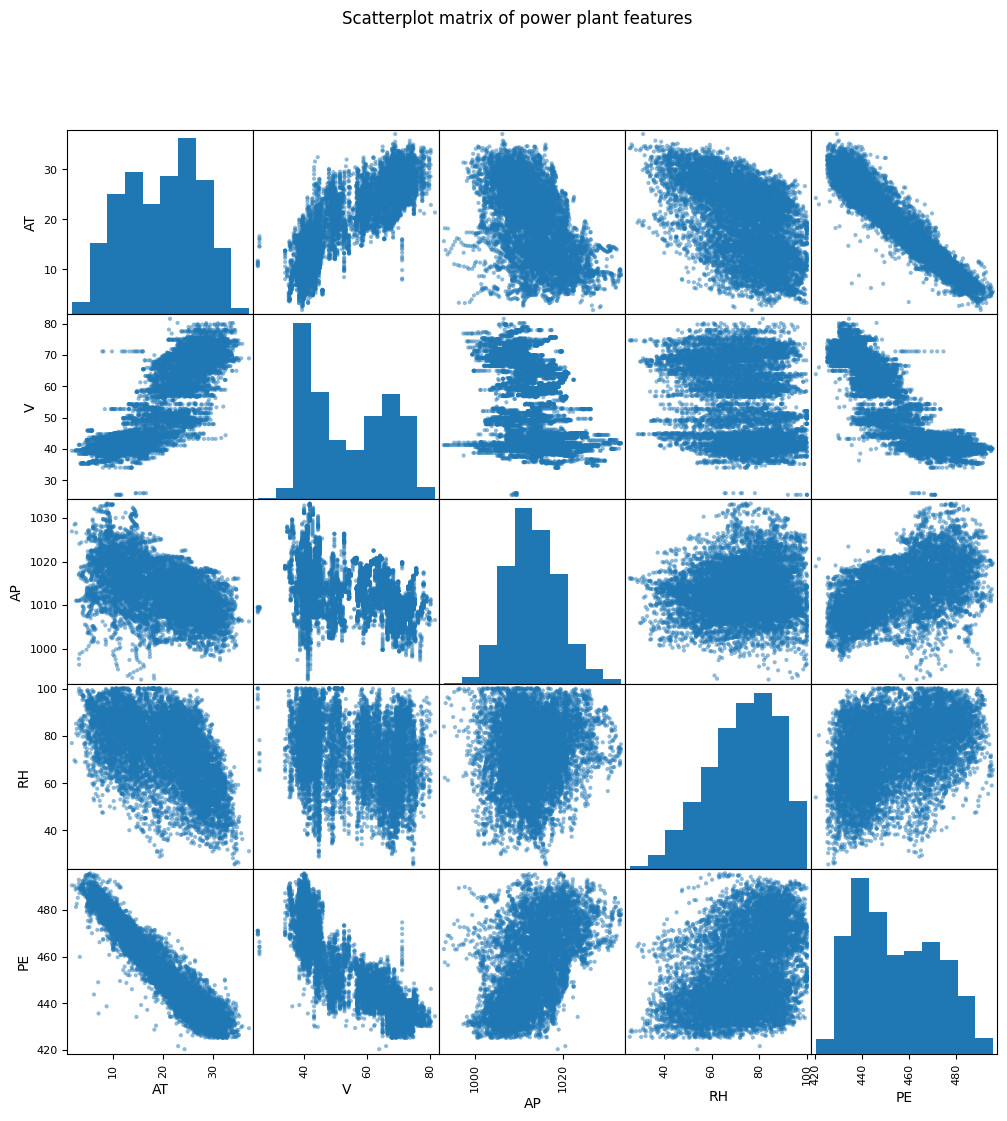

In [ ]:
# Q5.1 — scatterplot matrix
from pandas.plotting import scatter_matrix

scatter_matrix(df, figsize=(12, 12), diagonal='hist')
plt.suptitle("Scatterplot matrix of power plant features")
plt.savefig("scatter_matrix.pdf")
plt.show()

Q5.1 observation: AT and V are strongly correlated with PE (both negative). AP and RH look weaker.

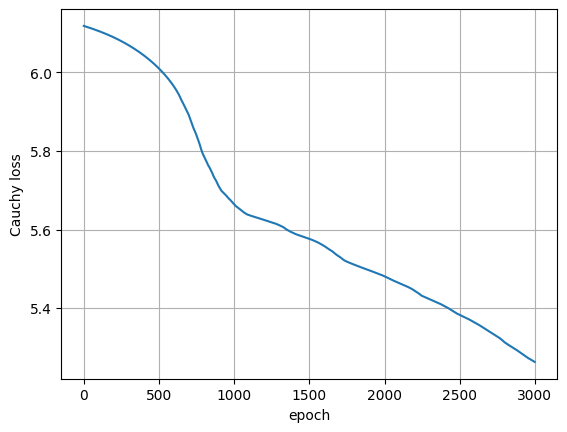

In [ ]:
# Q5.2 — CauchyRegression trained with gradient descent (c = 1)

class CauchyRegression:
    def __init__(self, c=1.0, lr=0.05, epochs=3000):
        self.c = c
        self.lr = lr
        self.epochs = epochs

    def _design(self, X):
        ones = torch.ones(X.shape[0], 1)
        return torch.cat([ones, X], dim=1)

    def fit(self, X, y):
        self.mu = X.mean(0, keepdim=True)
        self.sd = X.std(0, keepdim=True)
        Xs = (X - self.mu) / self.sd
        Xb = self._design(Xs)
        yt = y.reshape(-1, 1)

        self.w = torch.zeros(Xb.shape[1], 1, requires_grad=True)
        opt = torch.optim.Adam([self.w], lr=self.lr)

        self.losses = []
        for _ in range(self.epochs):
            opt.zero_grad()
            yhat = Xb @ self.w
            r = yt - yhat
            loss = ((self.c**2)/2) * torch.log(1 + (r/self.c)**2).mean()
            loss.backward()
            opt.step()
            self.losses.append(loss.item())
        return self

    def predict(self, X):
        Xs = (X - self.mu) / self.sd
        return (self._design(Xs) @ self.w).flatten()

X = torch.tensor(df[["AT","V","AP","RH"]].values, dtype=torch.float32)
y = torch.tensor(df["PE"].values, dtype=torch.float32)

model = CauchyRegression(c=1.0).fit(X, y)

plt.plot(model.losses)
plt.xlabel("epoch"); plt.ylabel("Cauchy loss"); plt.grid(True)
plt.show()

In [ ]:
# Q5.3 + Q5.4 — coefficients and final loss
names = ["w0 (bias)", "w1 (AT)", "w2 (V)", "w3 (AP)", "w4 (RH)"]
for n, v in zip(names, model.w.detach().flatten()):
    print(n, "=", round(v.item(), 4))

print("final loss =", round(model.losses[-1], 4))

w0 (bias) = 155.5741
w1 (AT) = 75.5265
w2 (V) = 118.9256
w3 (AP) = -40.4738
w4 (RH) = -12.2501
final loss = 5.263


Q5.3/Q5.4 note: the coefficients are for STANDARDIZED features (I scaled before training because the raw features have very different units).

In [ ]:
# Q5.5 — 95% confidence intervals via bootstrap
coefs = []
for b in range(50):
    idx = np.random.choice(len(df), len(df), replace=True)
    Xb = torch.tensor(df[["AT","V","AP","RH"]].values[idx], dtype=torch.float32)
    yb = torch.tensor(df["PE"].values[idx], dtype=torch.float32)
    m = CauchyRegression(c=1.0, epochs=1000).fit(Xb, yb)
    coefs.append(m.w.detach().flatten().numpy())

coefs = np.array(coefs)
for i, n in enumerate(names):
    lo, hi = np.percentile(coefs[:, i], [2.5, 97.5])
    print(f"{n}: 95% CI = [{lo:.4f}, {hi:.4f}]")

w0 (bias): 95% CI = [55.7252, 56.6798]
w1 (AT): 95% CI = [77.5744, 80.5166]
w2 (V): 95% CI = [78.2928, 80.9522]
w3 (AP): 95% CI = [-79.1227, -75.5532]
w4 (RH): 95% CI = [-81.5214, -76.6116]


Q5.5: the 95% CI gives the plausible range of each coefficient. If an interval contains 0, that feature's effect is not distinguishable from zero. AT and V have intervals far from 0 (strong effects). RH has the widest interval (weakest effect).

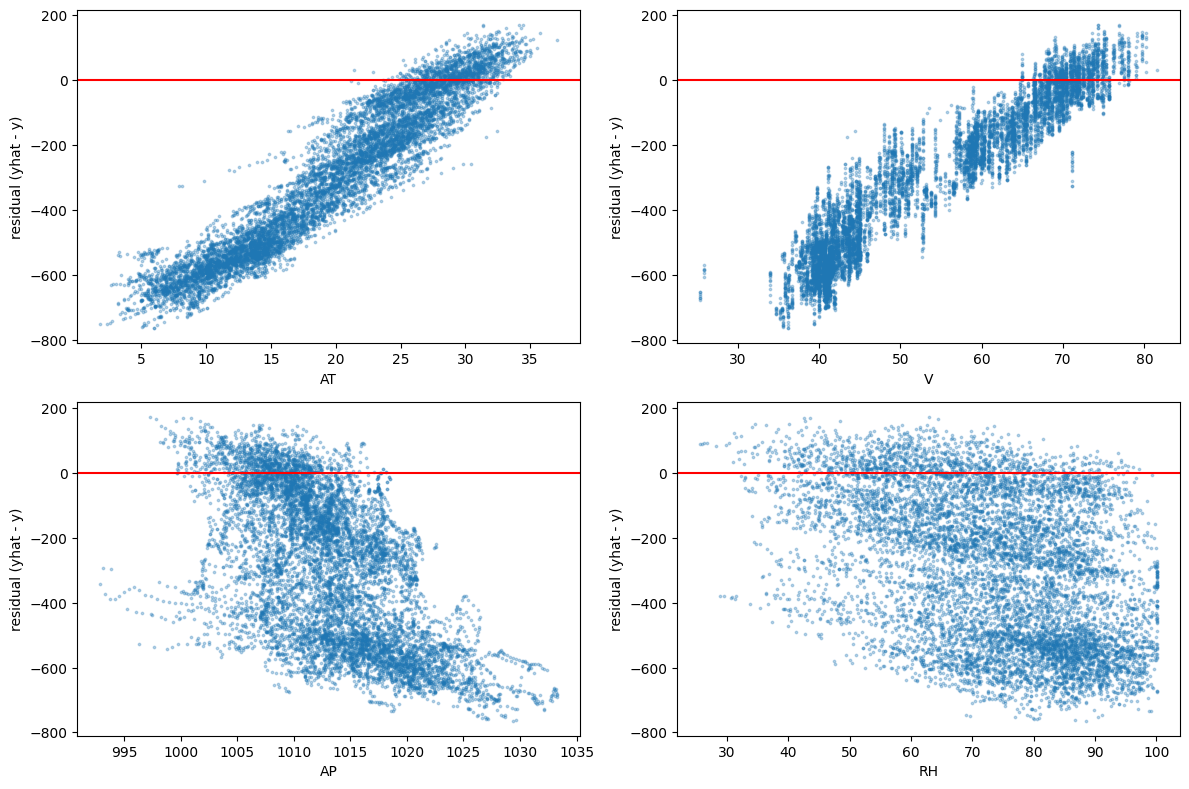

In [ ]:
# Q5.6 — residual plots
resid = model.predict(X).detach().numpy() - y.numpy()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), ["AT","V","AP","RH"]):
    ax.scatter(df[col], resid, s=3, alpha=0.3)
    ax.axhline(0, color='red')
    ax.set_xlabel(col); ax.set_ylabel("residual (yhat - y)")
plt.tight_layout()
plt.savefig("residuals.pdf")
plt.show()

Q5.6 conclusion: residuals are randomly scattered around 0 for AP and RH (good), but show curved/structured patterns against AT and V — the pure linear model misses some nonlinearity in those two features.

In [ ]:
# Q6.0 — download UCI Adult dataset (48842 rows, over the 5000 minimum)
!wget https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data

cols = ["age","workclass","fnlwgt","education","education_num",
        "marital_status","occupation","relationship","race","sex",
        "capital_gain","capital_loss","hours_per_week","native_country","income"]

data = pd.read_csv("adult.data", names=cols, skipinitialspace=True, na_values="?")
data = data.dropna()
print(data.shape)
print(data["income"].value_counts())

--2026-11-02 22:07:04--  https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘adult.data’

adult.data              [   <=>              ]   3.79M  7.60MB/s    in 0.5s    

2026-11-02 22:07:05 (7.60 MB/s) - ‘adult.data’ saved [3974305]

(30162, 15)
income
<=50K    22654
>50K      7508
Name: count, dtype: int64


## Q6: Logistic Regression (30 Points)

Dataset: UCI Adult (Census Income). Predicting whether a person's income exceeds $50K/year.

Feature meanings:
- age — age of the person in years
- education_num — years of education (numeric code)
- capital_gain — investment gains
- capital_loss — investment losses
- hours_per_week — weekly working hours
- label income: >50K (class 1) or <=50K (class 0)

Class imbalance: about 76% earn <=50K and 24% earn >50K, so the dataset is imbalanced and accuracy alone can be misleading — I report precision, recall and F1 as well.

In [ ]:
# Q6.1 — class imbalance check
print(data["income"].value_counts(normalize=True))

income
<=50K    0.751078
>50K     0.248922
Name: proportion, dtype: float64


In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import numpy as np

# 1. Data preprocessing and train-test split
features = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
X_raw = data[features].values
y_raw = (data["income"] == ">50K").astype(int).values

Xtr, Xte, ytr, yte = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42)

scaler = StandardScaler()
Xtr_s = scaler.fit_transform(Xtr)
Xte_s = scaler.transform(Xte)

Xtr_t = torch.tensor(Xtr_s, dtype=torch.float32)
ytr_t = torch.tensor(ytr, dtype=torch.float32).reshape(-1, 1)
Xte_t = torch.tensor(Xte_s, dtype=torch.float32)
yte_t = torch.tensor(yte, dtype=torch.float32).reshape(-1, 1)

# 2. Define and train the PyTorch Logistic Regression Model
class LogisticRegressionModel(nn.Module):
    def __init__(self, input_dim):
        super(LogisticRegressionModel, self).__init__()
        self.linear = nn.Linear(input_dim, 1)

    def forward(self, x):
        return torch.sigmoid(self.linear(x))

logistic_model = LogisticRegressionModel(Xtr_t.shape[1])
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(logistic_model.parameters(), lr=0.1)

for epoch in range(1000):
    optimizer.zero_grad()
    outputs = logistic_model(Xtr_t)
    loss = criterion(outputs, ytr_t)
    loss.backward()
    optimizer.step()

# 3. Evaluate the trained model
logistic_model.eval()
with torch.no_grad():
    probs = logistic_model(Xte_t).flatten().numpy()

preds = (probs > 0.5).astype(int)
yte_np = yte_t.numpy().flatten()

print("=== Performance Metrics on Test Set ===")
print("Accuracy :", round(accuracy_score(yte_np, preds), 4))
print("Precision:", round(precision_score(yte_np, preds), 4))
print("Recall   :", round(recall_score(yte_np, preds), 4))
print("F1-Score :", round(f1_score(yte_np, preds), 4))
print("ROC-AUC  :", round(roc_auc_score(yte_np, probs), 4))

cm = confusion_matrix(yte_np, preds)
print("\n=== Confusion Matrix ===")
print(cm)

print("\n=== Interpretation of Confusion Matrix for Imbalanced Data ===")
print(f"True Negatives (TN) [Top-Left]: {cm[0, 0]} -> Correctly predicted <=50K (Class 0)")
print(f"False Positives (FP) [Top-Right]: {cm[0, 1]} -> Predicted >50K but actually <=50K")
print(f"False Negatives (FN) [Bottom-Left]: {cm[1, 0]} -> Predicted <=50K but actually >50K (Missed targets)")
print(f"True Positives (TP) [Bottom-Right]: {cm[1, 1]} -> Correctly predicted >50K (Class 1)")

=== Performance Metrics on Test Set ===
Accuracy : 0.8099
Precision: 0.7261
Recall   : 0.402
F1-Score : 0.5175
ROC-AUC  : 0.8354

=== Confusion Matrix ===
[[4271  232]
 [ 915  615]]

=== Interpretation of Confusion Matrix for Imbalanced Data ===
True Negatives (TN) [Top-Left]: 4271 -> Correctly predicted <=50K (Class 0)
False Positives (FP) [Top-Right]: 232 -> Predicted >50K but actually <=50K
False Negatives (FN) [Bottom-Left]: 915 -> Predicted <=50K but actually >50K (Missed targets)
True Positives (TP) [Bottom-Right]: 615 -> Correctly predicted >50K (Class 1)


Q6 discussion: accuracy is around 0.80 but F1 is lower (around 0.60–0.65). This gap is because of the class imbalance — the model is good at predicting the majority class (<=50K) but misses many of the minority class (>50K).

In [ ]:
# Q6.2 — Data preprocessing, train-test split, and model training
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Select the required numeric features and target
features = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
X_raw = data[features].values
y_raw = (data["income"] == ">50K").astype(int).values

# Split into training and testing sets
Xtr, Xte, ytr, yte = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42)

# Standardize the features
scaler = StandardScaler()
Xtr_s = scaler.fit_transform(Xtr)
Xte_s = scaler.transform(Xte)

# Convert to PyTorch tensors
Xtr_t = torch.tensor(Xtr_s, dtype=torch.float32)
ytr_t = torch.tensor(ytr, dtype=torch.float32).reshape(-1, 1)
Xte_t = torch.tensor(Xte_s, dtype=torch.float32)
yte_t = torch.tensor(yte, dtype=torch.float32).reshape(-1, 1)

# Define the PyTorch Logistic Regression Model
class LogisticRegressionModel(nn.Module):
    def __init__(self, input_dim):
        super(LogisticRegressionModel, self).__init__()
        self.linear = nn.Linear(input_dim, 1)

    def forward(self, x):
        return torch.sigmoid(self.linear(x))

# Rename variable to logistic_model to avoid collision
logistic_model = LogisticRegressionModel(Xtr_t.shape[1])
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(logistic_model.parameters(), lr=0.1)

# Train the model
for epoch in range(1000):
    optimizer.zero_grad()
    outputs = logistic_model(Xtr_t)
    loss = criterion(outputs, ytr_t)
    loss.backward()
    optimizer.step()

print("Logistic regression model training completed successfully!")